# Individual homework project 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
customers=pd.read_csv('customers.csv')
transactions=pd.read_csv('transactions.csv')
campaign_touchpoints=pd.read_csv('campaign_touchpoints.csv')
web_sessions=pd.read_csv('web_sessions.csv')

### Specific questions

Q1. What is the average purchase value for customers from Spain?

In [3]:
merged=transactions.merge(customers, on='customer_id')
spain_avg_purchase=merged[merged['country']=='Spain']['purchase_value'].mean()
print(f"The average purchase value for customers in Spain is: ${spain_avg_purchase:.2f}")



The average purchase value for customers in Spain is: $230.96


Q2. What is the minimum purchase value for customers from Germany?

In [4]:
merged=transactions.merge(customers, on='customer_id')
germany_min_purchase=merged[merged['country']=='Germany']['purchase_value'].min()
print(f"The minimum purchase value for customers in Germany is: ${germany_min_purchase:.2f}")

The minimum purchase value for customers in Germany is: $10.01


Q3. How much did males spend on buying products in the Sports category?

In [5]:
merged=transactions.merge(customers, on='customer_id')
male_sports_spend=merged[(merged['gender']=='Male') & (merged['product_category']=='sports')]['purchase_value'].sum()
print(f"Total spent by male customers on Sports category: ${male_sports_spend:,.2f}")

Total spent by male customers on Sports category: $404,877.87


Q4. What is the average age of female customers from Canada?

In [6]:
canada_female_avg_age=customers[(customers['country']=='Canada') & (customers['gender']=='Female')]['age'].mean()
print(f" The average age of female customers in Canada is: {canada_female_avg_age:.2f} years")

 The average age of female customers in Canada is: 42.92 years


Q5. How much does an average male customer from the UK spend?

In [7]:
merged=transactions.merge(customers, on='customer_id')
uk_male_spend_per_customer=merged[(merged['gender']=='Male') & (merged['country']=='UK')].groupby('customer_id')['purchase_value'].sum()
avg_uk_male_spend=uk_male_spend_per_customer.mean()
print(f"The average total spend of a male customer from the UK is: ${avg_uk_male_spend:.2f}")

The average total spend of a male customer from the UK is: $1051.55


Q6. What is the maximum purchase value for females in the Toys category?

In [8]:
merged=transactions.merge(customers, on='customer_id')
female_toys_max_purchase=merged[(merged['gender']=='Female') & (merged['product_category']=='toys')]['purchase_value'].max()
print(f"The maximum purchase value for females in the Toys category is: ${female_toys_max_purchase:.2f}")

The maximum purchase value for females in the Toys category is: $79.99


Q7. What is the average number of pages viewed for customers who made a purchase (converted)?

In [9]:
avg_pages_converted=web_sessions[web_sessions['converted']==1]['pages_viewed'].mean()
print(f"The average number of pages viewed for converted sessions is: {avg_pages_converted:.2f}")

The average number of pages viewed for converted sessions is: 5.73


Q8. What is the average time spent on the site for purchasing vs non-purchasing customers?

In [10]:
avg_time_by_conversion=web_sessions.groupby('converted')['time_on_site'].mean()
print(avg_time_by_conversion)

converted
0    299.238547
1    311.194837
Name: time_on_site, dtype: float64


### Visualisation tasks

Q9. Plot purchasing value across years.

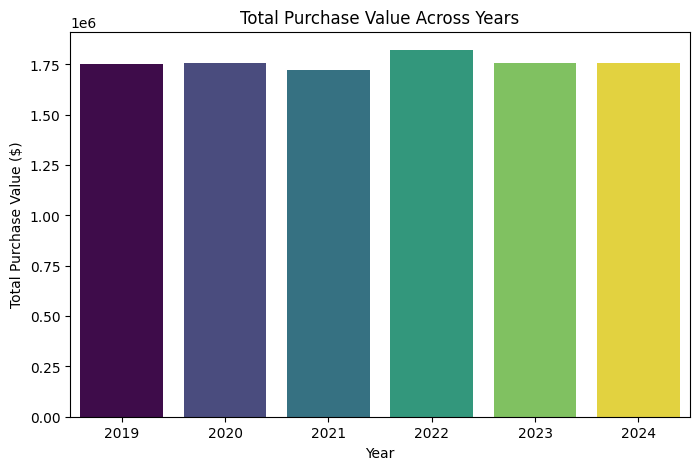

In [11]:
transactions['year'] = pd.to_datetime(transactions['purchase_date']).dt.year
yearly_purchase = transactions.groupby('year')['purchase_value'].sum().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=yearly_purchase, x='year', y='purchase_value', palette='viridis', hue='year', legend=False)
plt.title('Total Purchase Value Across Years')
plt.xlabel('Year')
plt.ylabel('Total Purchase Value ($)')
plt.show()

Q10. Plot purchasing value across product categories.

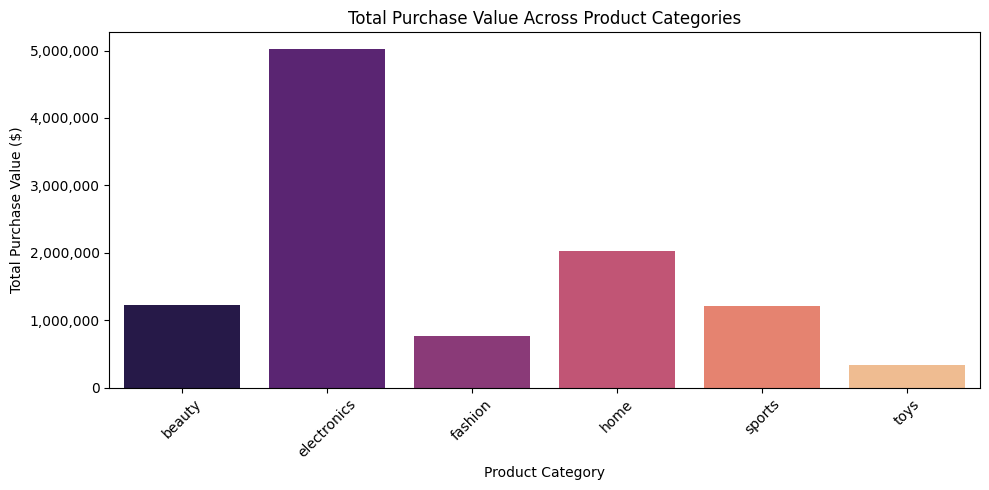

In [12]:
cat_purchase = transactions.groupby('product_category')['purchase_value'].sum().reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=cat_purchase, x='product_category', y='purchase_value', palette='magma', hue='product_category', legend=False)
plt.title('Total Purchase Value Across Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Total Purchase Value ($)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x:,.0f}"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Free exercise

Explore the transactions dataset and:

- Create two visualisations of your choice
- Identify three patterns in the data
- Write five insights in plain English explaining what the data tells us

Your insights should focus on behaviour, spending patterns, or conversion

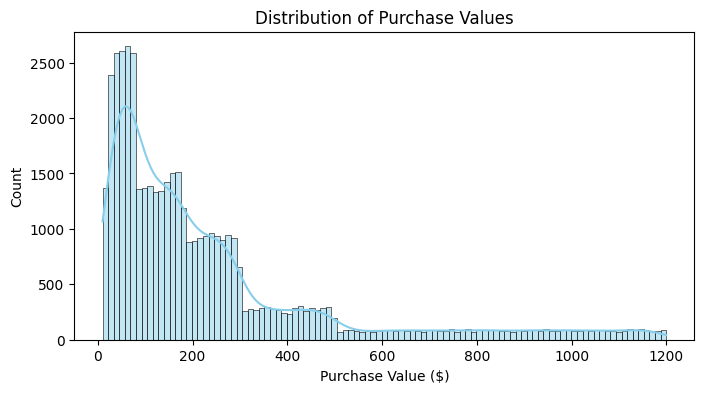

In [13]:

plt.figure(figsize=(8, 4))
sns.histplot(transactions['purchase_value'], kde=True, color='skyblue')
plt.title('Distribution of Purchase Values')
plt.xlabel('Purchase Value ($)')
plt.show()

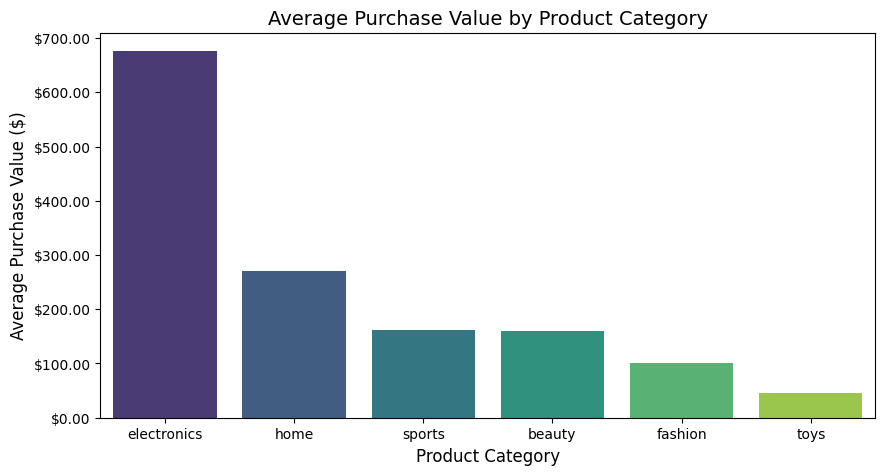

In [14]:
category_avg_value = transactions.groupby('product_category')['purchase_value'].mean().reset_index().sort_values(by='purchase_value', ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=category_avg_value, x='product_category', y='purchase_value', palette='viridis', hue='product_category', legend=False)
plt.title('Average Purchase Value by Product Category', fontsize=14)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Average Purchase Value ($)', fontsize=12)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"${x:,.2f}"))
plt.show()

   1. Three patterns

     -Electronics has the highest average purchase value, at 676.21.

     -Toys has the lowest average purchase value, at 45.43.

     -Average purchase values are very similar with and without discounts, with only a small difference between the two groups.

   2. Five insights

     -Product categories differ in spending: Electronics has a much higher average purchase value than the other categories, while Toys has the lowest.

     -Discounts show little difference in average purchase value: Transactions with discounts average 235.61, compared with 234.56 without discounts. This alone does not tell us whether discounts increase sales.

     -Category performance deserves further investigation: Comparing both the average and total purchase value by category can help identify which categories contribute most to sales.

     -Sales trends over time deserve attention: Comparing purchase values across years or months can help reveal changes in spending.

     -Unusual transactions deserve investigation: Checking unusually high or low purchase values and refund-related records may reveal data errors or transactions that need further review.
